In [1]:
import tensorflow as tf

print(tf.__version__)

2.21.0


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [3]:
df = pd.read_csv('Churn_Modelling.csv')

In [4]:
df.head()

,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [5]:
df.shape

(10000, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [7]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [15]:
# drop unwanted colulmns RowNumber, CustomerId and surname
df.drop(columns=['RowNumber','CustomerId','Surname'],inplace=True)

In [16]:
df.head()

,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [27]:
df = pd.get_dummies(df,columns=['Geography','Gender'],drop_first=True,dtype=int)

In [28]:
X=df.drop(columns=['Exited'])
y=df['Exited']

In [29]:
X

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...
9995,771,39,5,0.00,2,1,0,96270.64,0,0,1
9996,516,35,10,57369.61,1,1,1,101699.77,0,0,1
9997,709,36,7,0.00,1,0,1,42085.58,0,0,0
9998,772,42,3,75075.31,2,1,0,92888.52,1,0,1


In [30]:
y

0       1
1       0
2       1
3       0
4       0
       ..
9995    0
9996    0
9997    1
9998    1
9999    0
Name: Exited, Length: 10000, dtype: int64

In [31]:
X_train,X_test,y_train,y_test = train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [32]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [33]:
import tensorflow
from tensorflow import keras
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Dense

In [59]:
model = Sequential()

model.add(Dense(5,activation='relu',input_dim=11))

model.add(Dense(1,activation='sigmoid'))

D:\anaconda3\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


In [60]:
model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                      │ (None, 5)                   │              60 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │               6 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 66 (264.00 B)

 Trainable params: 66 (264.00 B)

 Non-trainable params: 0 (0.00 B)

In [61]:
model.compile(loss='binary_crossentropy',optimizer='Adam',metrics=['accuracy'])

In [62]:
history = model.fit(X_train_scaled,y_train,epochs=100,validation_split=0.2)

Epoch 1/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.6837 - loss: 0.6432 - val_accuracy: 0.7644 - val_loss: 0.5630
Epoch 2/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.7923 - loss: 0.5319 - val_accuracy: 0.8081 - val_loss: 0.4885
Epoch 3/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8103 - loss: 0.4823 - val_accuracy: 0.8200 - val_loss: 0.4531
Epoch 4/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8125 - loss: 0.4576 - val_accuracy: 0.8263 - val_loss: 0.4372
Epoch 5/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8138 - loss: 0.4425 - val_accuracy: 0.8281 - val_loss: 0.4270
Epoch 6/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step - accuracy: 0.8172 - loss: 0.4315 - val_accuracy: 0.8313 - val_loss: 0.4199
Epoch 7/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8188 - loss: 0.4223 - val_accuracy: 0.8350 - val_loss: 0.4127
Epoch 8/100
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8247 - loss: 0.4139 - val_accu

In [64]:
model.layers[0].get_weights()

[array([[ 4.36934605e-02, -1.07185178e-01, -3.01358737e-02,
         -1.49235979e-03,  1.04675628e-01],
        [-1.20414615e+00,  3.41033846e-01,  3.70498933e-02,
          2.44175252e-02,  5.55695474e-01],
        [-2.30221730e-02, -2.99698710e-01, -4.99338694e-02,
         -5.90645038e-02,  2.20339447e-01],
        [-2.46147206e-03, -3.63503285e-02,  3.61245632e-01,
         -3.51563483e-01, -1.54133141e-02],
        [ 1.41781777e-01,  1.05050504e-01,  1.37428761e+00,
         -1.50987434e+00,  1.87034532e-01],
        [-4.37905155e-02, -2.55532376e-02, -2.90422961e-02,
          3.36103630e-03,  1.49291575e-01],
        [-4.44426239e-01,  6.85031414e-01, -6.75170720e-02,
         -3.70991439e-01,  9.58605886e-01],
        [ 5.33125177e-02,  3.35462421e-01,  8.09283778e-02,
          1.54567540e-01,  5.49175739e-02],
        [-6.63683191e-02,  6.63002253e-01, -5.25546186e-02,
          4.66350496e-01, -3.55850637e-01],
        [-1.11414038e-01,  3.51839066e-01,  3.72205861e-02,
    

In [65]:
y_log = model.predict(X_test_scaled)

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [66]:
y_pred = np.where(y_log>0.5,1,0)

In [68]:
from sklearn.metrics import accuracy_score
accuracy_score(y_test,y_pred)

0.861

In [74]:
import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rcParams['font.enable_last_resort'] = False

In [75]:
history.history

{'accuracy': [0.6837499737739563,
  0.7923437356948853,
  0.8103125095367432,
  0.8125,
  0.8137500286102295,
  0.817187488079071,
  0.8187500238418579,
  0.8246874809265137,
  0.8298437595367432,
  0.832812488079071,
  0.840624988079071,
  0.844531238079071,
  0.8470312356948853,
  0.8504687547683716,
  0.8520312309265137,
  0.8535937666893005,
  0.8557812571525574,
  0.8570312261581421,
  0.8576562404632568,
  0.8571875095367432,
  0.8581249713897705,
  0.8578125238418579,
  0.8581249713897705,
  0.8587499856948853,
  0.860156238079071,
  0.859375,
  0.8590624928474426,
  0.8592187762260437,
  0.8584374785423279,
  0.8587499856948853,
  0.8589062690734863,
  0.8589062690734863,
  0.8587499856948853,
  0.8604687452316284,
  0.8596875071525574,
  0.8595312237739563,
  0.8604687452316284,
  0.8590624928474426,
  0.8607812523841858,
  0.8589062690734863,
  0.8592187762260437,
  0.8606250286102295,
  0.8603125214576721,
  0.8584374785423279,
  0.8592187762260437,
  0.8604687452316284,
  0

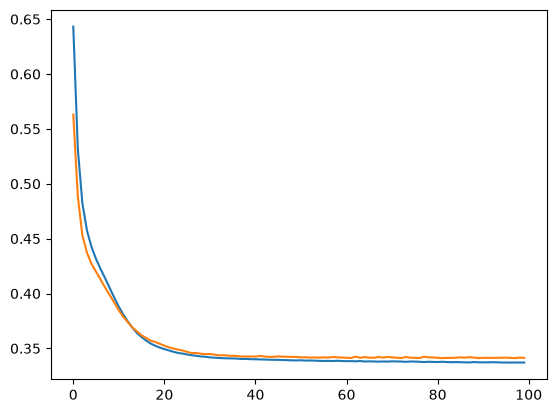

In [77]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

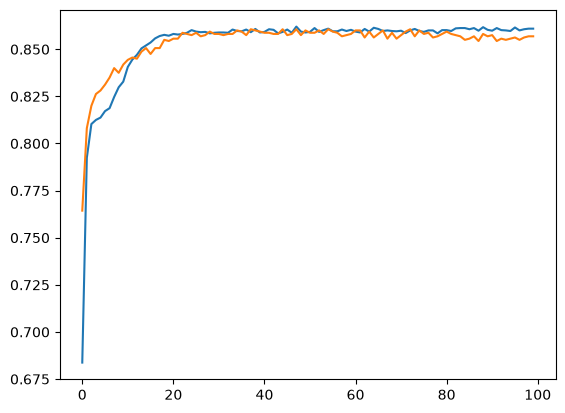

In [78]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])